In [1]:
import random
import numpy as np
from PIL import Image as PILImage, ImageFilter
from scipy import ndimage
from skimage.measure import label
from matplotlib import pyplot as plt

In [2]:
IMG_SIZE = 26
BORDER = 1

In [12]:
class Line:
    def __init__(self, line_id, image_id):
        self.line_id = line_id
        self.image_id = image_id
        self.segments = []

class Image:
    def __init__(self, num_lines, thickness, image_id):
        self.num_lines = num_lines
        self.thickness = thickness
        self.image_id = image_id
        self.lines = [Line(line_id, image_id) for line_id in range(1, num_lines + 1)]
        self.grid = np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.int32)

        #print("thickness", self.thickness)
        for line_id, line in enumerate(self.lines):
            self.add_line(line_id)

    def add_line(self, line_id):
        temp_grid = np.zeros(self.grid.shape).astype(self.grid.dtype)
        oldgrid = np.copy(self.grid)
        line = self.lines[line_id]

        for i in range(50):
            # chose starting point
            buffer = self.thickness - 1
            y = random.randint(buffer, max(buffer + 1, IMG_SIZE - buffer - 1))
            x = random.randint(buffer, max(buffer + 1, IMG_SIZE - buffer - 1))

            if self.grid[y, x] == 0:
                max_length = max(1, (13 * 13) // (self.thickness * self.thickness))
                num_segments = random.randint(1, max_length + 1)

                ny = y
                nx = x

                #print("line", line_id, "start", x, y, "num segments", num_segments)
                last_dir = -1
                for segment_id in range(num_segments):
                    if max_length < 1:
                        break

                    length = random.randint(1, 26)
                    slope = random.randint(1, 45) / 45

                    direction = last_dir
                    dirdt = random.randint(-1,1)

                    if last_dir == -1:
                        direction = random.randint(0,7)

                    elif direction == 0 and dirdt == -1:
                        direction = 7
                            
                    elif direction == 7 and dirdt == 1:
                        direction = 0

                    else:
                        direction += dirdt
                    
                    last_dir = direction
                    #print("direction", direction)
                    #direction = random.randint(0,7)

                    
                    seg_thickness = self.thickness
                    segth = seg_thickness // 2 + 1

                    newlength = 0
                    ty = y
                    tx = x
                    while True:
                        if ty < 0 or ty > IMG_SIZE - 1:
                            break
                        if tx < 0 or tx > IMG_SIZE - 1:
                            break
                        newlength += seg_thickness // 2 + 1

                        if direction == 0:
                            ty = ty + slope * segth
                            tx = tx + segth
                        elif direction == 1:
                            ty = ty - segth
                            tx = tx + slope * segth
                        elif direction == 2:
                            ty = ty - segth
                            tx = tx - slope * segth
                        elif direction == 3:
                            ty = ty - slope * segth
                            tx = tx - segth
                        elif direction == 4:
                            ty = ty + slope * segth
                            tx = tx - segth
                        elif direction == 5:
                            ty = ty + segth
                            tx = tx - slope * segth
                        elif direction == 6:
                            ty = ty + segth
                            tx = tx + slope * segth
                        elif direction == 7:
                            ty = ty - slope * segth
                            tx = tx + segth

                        

                    length = newlength
                    #print("  segment", segment_id, length, slope, direction)

                    for step in range(length):
                        if direction == 0:
                            ny = ny + slope * (seg_thickness // 2 + 1)
                            nx = nx + segth
                        elif direction == 1:
                            ny = ny - seg_thickness // 2 + 1
                            nx = nx + slope * (seg_thickness // 2 + 1)
                        elif direction == 2:
                            ny = ny - segth
                            nx = nx - slope * (seg_thickness // 2 + 1)
                        elif direction == 3:
                            ny = ny - slope * (seg_thickness // 2 + 1)
                            nx = nx - segth
                        elif direction == 4:
                            ny = ny + slope * (seg_thickness // 2 + 1)
                            nx = nx - segth
                        elif direction == 5:
                            ny = ny + segth
                            nx = nx - slope * (seg_thickness // 2 + 1)
                        elif direction == 6:
                            ny = ny + segth
                            nx = nx + slope * (seg_thickness // 2 + 1)
                        elif direction == 7:
                            ny = ny - slope * (seg_thickness // 2 + 1)
                            nx = nx + segth

                        dt = seg_thickness // 2 + 1
                        #if slope < 1 and seg_thickness < 1:
                        #    dt = 2

                        #print(nx, ny)

                        if ny < 0 or ny > 26 or nx < 0 or nx > 26 or np.any(temp_grid[int(ny):int(ny) + 1, int(nx):int(nx) + 1] == 1):
                            line.segments.append({
                                "segment_id": segment_id,
                                "length": step,
                                "slope": slope,
                                "direction": direction,
                            })
                            max_length = max_length - step

                            break

                        if step == length-1:
                            line.segments.append({
                                "segment_id": segment_id,
                                "length": step,
                                "slope": slope,
                                "direction": direction,
                            })
                        temp_grid[int(ny) - dt:int(ny) + dt + 1, int(nx) - dt:int(nx) + dt + 1] = 1

                    #print("step", segment_id, line.segments[segment_id])

                    max_length = max_length - length

                    self.grid = np.clip(self.grid + temp_grid, 0, 1)

                break

        newgrid = np.copy(np.clip(self.grid + temp_grid, 0, 1))
        newlines = np.clip(newgrid - oldgrid, 0, 1)
        newlines = ndimage.binary_dilation(newlines)

        newlines_label = label(newlines)
        newlines_label_m = newlines_label == 1
        newlines_label_m2 = newlines_label_m.astype(int)
        newlines_label_m2e = ndimage.binary_erosion(newlines)
        self.grid = np.clip(oldgrid + newlines_label_m2e, 0, 1)



In [13]:
def postprocess(grid):
    arr = np.array(grid, dtype=np.uint8) * 255
    rows = np.any(arr > 0, axis=1)
    cols = np.any(arr > 0, axis=0)
    if rows.any() and cols.any():
        rmin, rmax = np.where(rows)[0][[0, -1]]
        cmin, cmax = np.where(cols)[0][[0, -1]]
        h = rmax - rmin + 1
        w = cmax - cmin + 1
        is_full_image = (rmin == 0 and rmax == IMG_SIZE - 1 and cmin == 0 and cmax == IMG_SIZE - 1)
        offset_y = (28 - h) // 2 - rmin
        offset_x = (28 - w) // 2 - cmin
        centered = np.zeros((28, 28), dtype=np.uint8)
        sy1, sy2 = max(0, -offset_y), min(IMG_SIZE, IMG_SIZE - offset_y)
        sx1, sx2 = max(0, -offset_x), min(IMG_SIZE, IMG_SIZE - offset_x)
        dy1, dy2 = max(0, offset_y), min(28, 28 + offset_y)
        dx1, dx2 = max(0, offset_x), min(28, 28 + offset_x)
        h_copy = min(sy2 - sy1, dy2 - dy1)
        w_copy = min(sx2 - sx1, dx2 - dx1)
        if h_copy > 0 and w_copy > 0:
            centered[dy1:dy1+h_copy, dx1:dx1+w_copy] = arr[sy1:sy1+h_copy, sx1:sx1+w_copy]
    else:
        centered = np.zeros((28, 28), dtype=np.uint8)
        is_full_image = False

    pil_img = PILImage.fromarray(centered)
    pil_img = pil_img.filter(ImageFilter.GaussianBlur(radius=0.5))
    arr = np.array(pil_img)
    arr[:BORDER, :] = 0
    arr[-BORDER:, :] = 0
    arr[:, :BORDER] = 0
    arr[:, -BORDER:] = 0
    return arr, not is_full_image

[153.]
False


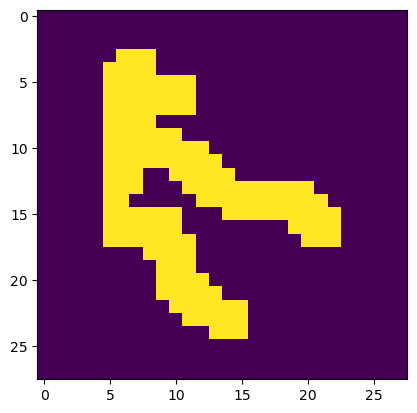

In [243]:
num_lines = random.randint(1, 26)
thickness = random.randint(2, max(2, 13 // num_lines))
thickness = 1
image = Image(num_lines, thickness, 1)
img = image.grid
img2, centered = postprocess(img)
#plt.imshow(img, interpolation='nearest');plt.show()

# Label connected components of white pixels
binary = (img2 > 127).astype(int)
labeled, num_features = ndimage.label(binary)
#plt.imshow(binary, interpolation='nearest');plt.show()
#plt.imshow(labeled, interpolation='nearest');plt.show()

# Calculate sizes of all white components
sizes = ndimage.sum(binary, labeled, range(1, num_features + 1))

# Check if any white component is "large" (e.g., > 20% of image)
image_size = img2.shape[0] * img2.shape[1]
large_threshold = image_size * 0.2

print(sizes)
has_large_white_area = np.any(sizes > large_threshold)
print(has_large_white_area)
img2 = (img2 > 128)


plt.imshow(img2, interpolation='nearest');plt.show()

In [6]:
                    direction = last_dir
                    dirdt = random.randint(-1,1)

                    if last_dir == -1:
                        direction = random.randint(0,7)

                    elif direction == 0 and dirdt == -1:
                        direction = 8
                            
                    elif direction == 7 and dirdt == 1:
                        direction = 0

                    else:
                        direction += dirdt
                    
                    last_dir = direction

NameError: name 'last_dir' is not defined

In [7]:
random.randint(-1,1)

0

(28, 28)


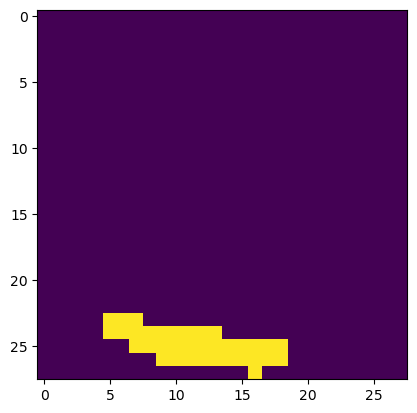

In [234]:
img = np.zeros((26,26), dtype="float32")
x = np.random.randint(0,25)
y = np.random.randint(0,13)
direction = np.random.randint(4, 8)

if direction == 4:
    slope = np.random.randint(0,44)/45
elif direction == 5:
    slope = np.random.randint(0, 44)/45
elif direction == 6:
    slope = np.random.randint(0,44)/45
elif direction == 7:
    slope = np.random.randint(0,44)/45
    
#print(direction, slope)

#img[y,x] = 1

length = np.random.randint(1,26)

nx = x
ny = y
seglength = 1
step = 0
segmentid = 0

while length > 0:
    length -= 1
    step += 1
    
    if direction == 0:
        ny = ny + slope
        nx = nx + 1
    if direction == 1:
        ny = ny - 1
        nx = nx + slope
    if direction == 2:
        ny = ny - 1
        nx = nx - slope
    if direction == 3:
        ny = ny - slope
        nx = nx - 1
    if direction == 4:
        ny = ny + slope
        nx = nx - 1
    if direction == 5:
        ny = ny + 1
        nx = nx - slope
    if direction == 6:
        ny = ny + 1
        nx = nx + slope
    if direction == 7:
        ny = ny + slope
        nx = nx + 1
        
    if 25 < nx or nx < 0 or 25 < ny or ny < 0:
        break

    if step > 1:
        img[int(ny), int(nx)] = segmentid
    else:
        img[int(ny), int(nx)] = 0

    if seglength == 0:
        dirchange = np.random.randint(-1,2)
        if direction == 0 and dirchange == -1:
            direction = 7
        if direction == 7 and dirchange == 1:
            direction = 0
        else:
            direction += dirchange
        slope = np.random.randint(0,44)/45

        seglength = np.random.randint(2,13)
        length = seglength
        segmentid += 1
    seglength -= 1
    
rot = np.random.randint(0,4)
if rot == 1:
    img = np.rot90(img)
elif rot == 2:
    img = np.rot90(np.rot90(img))
elif rot == 3:
    img = np.rot90(np.rot90(np.rot90((img))))

img = np.clip(img, 0, 1)
img = ndimage.binary_dilation(img)

arr = np.array(img, dtype=np.uint8) * 255
pil_img = PILImage.fromarray(arr)
pil_img = pil_img.filter(ImageFilter.GaussianBlur(radius=0.57))
img = np.array(pil_img)
img = (img > 195).astype(int)
img, centered = postprocess(img)
print(img.shape)
imgb = np.zeros((2*28,2*28), dtype="float32")
tx = np.random.randint(0, 28)
ty = np.random.randint(0, 28)
imgb[ty:ty+28, tx:tx+28] = img
img = imgb[13:28+13,13:28+13]
img = (img > 128)

plt.imshow(img, interpolation='nearest');plt.show()

In [24]:
img = np.zeros((26,26), dtype="float32")
x = np.random.randint(0,25)
y = np.random.randint(0,13)
direction = np.random.randint(4, 8)

if direction == 4:
    slope = np.random.randint(0,44)/45
elif direction == 5:
    slope = np.random.randint(0, 44)/45
elif direction == 6:
    slope = np.random.randint(0,44)/45
elif direction == 7:
    slope = np.random.randint(0,44)/45
    
#print(direction, slope)

#img[y,x] = 1

length = np.random.randint(1,26)

nx = x
ny = y
seglength = 1
step = 0
segmentid = 0
segments = []

while length > 0:
    length -= 1
    step += 1
    
    if direction == 0:
        ny = ny + slope
        nx = nx + 1
    if direction == 1:
        ny = ny - 1
        nx = nx + slope
    if direction == 2:
        ny = ny - 1
        nx = nx - slope
    if direction == 3:
        ny = ny - slope
        nx = nx - 1
    if direction == 4:
        ny = ny + slope
        nx = nx - 1
    if direction == 5:
        ny = ny + 1
        nx = nx - slope
    if direction == 6:
        ny = ny + 1
        nx = nx + slope
    if direction == 7:
        ny = ny + slope
        nx = nx + 1
        
    if 25 < nx or nx < 0 or 25 < ny or ny < 0:
        break

    if step > 1:
        img[int(ny), int(nx)] = segmentid
    else:
        img[int(ny), int(nx)] = 0

    if seglength == 0:
        dirchange = np.random.randint(-1,2)
        if direction == 0 and dirchange == -1:
            direction = 7
        if direction == 7 and dirchange == 1:
            direction = 0
        else:
            direction += dirchange
        slope = np.random.randint(0,44)/45

        seglength = np.random.randint(2,13)
        length = seglength
        segmentid += 1
        segments.append(length)
    seglength -= 1
    
rot = np.random.randint(0,4)
if rot == 1:
    img = np.rot90(img)
elif rot == 2:
    img = np.rot90(np.rot90(img))
elif rot == 3:
    img = np.rot90(np.rot90(np.rot90((img))))

#plt.imshow(img, interpolation='nearest');plt.show()
img = np.clip(img, 0, 1)
img = ndimage.binary_dilation(img)

arr = np.array(img, dtype=np.uint8) * 255
pil_img = PILImage.fromarray(arr)
pil_img = pil_img.filter(ImageFilter.GaussianBlur(radius=0.57))
img = np.array(pil_img)
img = (img > 195).astype(int)

rows = np.any(arr > 0, axis=1)
cols = np.any(arr > 0, axis=0)
if rows.any() and cols.any():
    rmin, rmax = np.where(rows)[0][[0, -1]]
    cmin, cmax = np.where(cols)[0][[0, -1]]
print(rmin, rmax, cmin, cmax)

if np.random.randint(0,2) == 0:
    roll = np.random.randint(0,rmin+1)
    img = np.roll(img, -roll, 0)
    print("roll r0:", roll)
else:
    roll = np.random.randint(0, 26-rmax)
    img = np.roll(img, roll, 0)
    print("roll r1:", roll)

if np.random.randint(0,2) == 0:
    roll = np.random.randint(0,cmin+1)
    img = np.roll(img, -roll, 1)
    print("roll c0:", roll)
else:
    roll = np.random.randint(0, 26-cmax)
    img = np.roll(img, roll, 1)
    print("roll c1:", roll)

print(segments)
plt.imshow(img);plt.show()

NameError: name 'rmin' is not defined

In [25]:
np.random.randint(0,2)

0

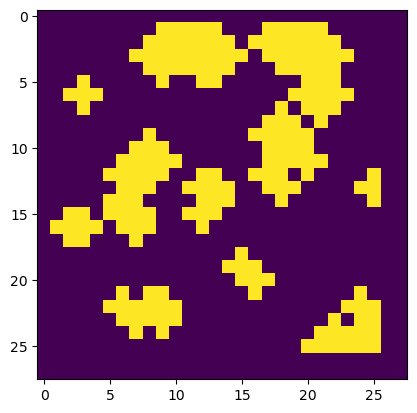

In [268]:
imgr = np.random.randint(0,2,(26,26))
imgra = ndimage.binary_dilation(imgr)
imgra = ndimage.binary_erosion(imgra)
imgra = imgra * (-1) + 1

imgrb = ndimage.binary_erosion(imgr)
imgrb = ndimage.binary_dilation(imgrb)
imgrb = ndimage.binary_dilation(imgrb)
#imgrb = imgrb * (-1) + 1

imgr = imgra + imgrb
imgr = np.clip(imgr, 0, 1) #* (-1) + 1
imgr = ndimage.binary_erosion(imgr)
imgr = ndimage.binary_dilation(imgr)
imgr, centered = postprocess(imgr)
imgr = imgr.astype(np.float32) / 255
imgr = (imgr > 0.5)

plt.imshow(imgr);plt.show()

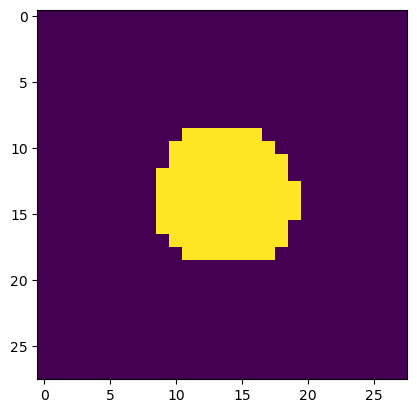

In [12]:
img = np.load("./test_data/class_0/000017.npy")
img = img / 255
img = (img > 0.5).astype(np.float32)
plt.imshow(img);plt.show()

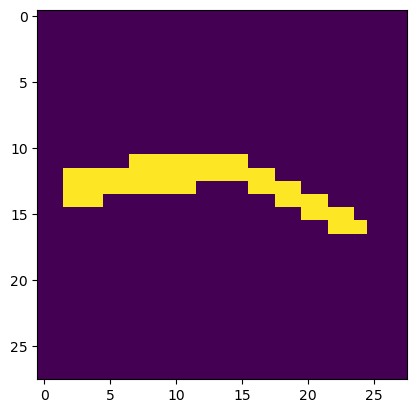

In [7]:
img = np.load("./data/class_1/000004.npy")
img = img / 255
img = (img > 0.5).astype(np.float32)
plt.imshow(img);plt.show()

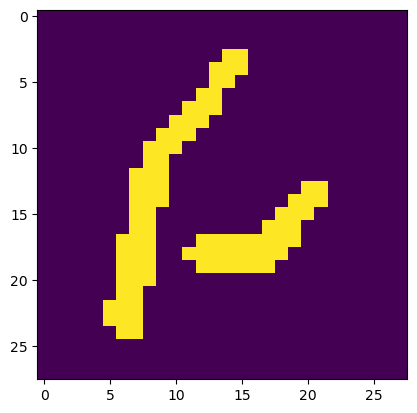

In [10]:
img = np.load("./data/class_2/000002.npy")
img = img / 255
img = (img > 0.5).astype(np.float32)
plt.imshow(img);plt.show()